# Risk and Return: investigación reproducible de carteras

Este notebook demuestra el mismo motor local que `python -m risk_return`. Instalá
el proyecto y ejecutá las celdas en orden desde un kernel limpio. No usa descargas,
cuentas ni datos privados. Las salidas son ejemplos **sintéticos** regenerados,
no un historial de rentabilidad de inversiones. Ver README y docs/DATA.md.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from risk_return.core import Config, synthetic_dataset, run_experiment, optimize_weights, simulate_buy_and_hold


## 1. Datos inventados y trazables

Tres trayectorias deterministas en USD simulados, sin calibración con datos de mercado.
Las fechas hábiles no incluyen feriados bursátiles. La metadata distingue datos
sintéticos, unidades y procedencia de observaciones reales.

In [2]:
prices, metadata = synthetic_dataset()
display(pd.Series({k: metadata[k] for k in ["kind", "currency", "coverage_start", "coverage_end", "source"]}))
display(prices.head())


kind                                       synthetic
currency                                         USD
coverage_start                            2020-01-02
coverage_end                              2021-06-16
source            risk_return.core.synthetic_dataset
dtype: str

,Asset_A,Asset_B,Asset_C
date,,,
2020-01-02,100.000000,50.000000,200.000000
2020-01-03,100.450000,50.330794,202.343016
2020-01-06,101.037705,50.668389,204.650894
2020-01-07,101.760827,50.998534,206.879468
2020-01-08,102.613664,51.308048,208.984984


## 2. Definir el experimento antes de mirar la prueba

Se estima con 252 retornos de entrenamiento y se evalúan los 126 siguientes. Cada
bloque tiene su precio inicial. La compra ocurre al cierre siguiente al entrenamiento;
no se gana el salto entre ambos cierres. Todas las reglas usan los mismos activos
elegibles en entrenamiento y fechas. El peso inicial máximo es 60%, sin cortos ni deuda.

In [3]:
config = Config(train_periods=252, test_periods=126, max_weight=0.60,
                initial_capital=10000.0, cost_bps=10.0, risk_free_annual=0.0)
result = run_experiment(prices, metadata, config)
display(pd.Series(result["quality"]))
assert result["metrics"]["status"].eq("ok").all()


input_assets                                                 3
eligible_training                  [Asset_A, Asset_B, Asset_C]
excluded_training                                           []
missing_input_prices                                         0
missing_test_prices                                         {}
train_start                                         2020-01-02
train_end                                           2020-12-21
test_start                                          2020-12-22
test_end                                            2021-06-16
calendar_verified                                        False
metadata_independently_verified                          False
dtype: object

## 3. Comparar decisiones

La asignación equiponderada es una referencia simple. Mínima volatilidad minimiza
`wᵀΣw`; máximo Sharpe minimiza el negativo del ratio con medias aritméticas anualizadas.
Se verifican restricciones y éxito del optimizador. El redondeo es solo de presentación.
El límite aplica al comprar: los pesos pueden cambiar después con los precios.

In [4]:
weights = result["weights"].pivot(index="asset", columns="strategy", values="weight")
display(weights.round(6))
assert np.allclose(weights.sum(), 1.0)
assert (weights <= config.max_weight + 1e-8).all().all()


strategy,equal_weight,max_sharpe,min_volatility
asset,,,
Asset_A,0.333333,0.4,0.186328
Asset_B,0.333333,0.6,0.600000
Asset_C,0.333333,0.0,0.213672


## 4. Una trayectoria neta para todas las métricas realizadas

Se mantienen unidades ajustadas fijas hasta liquidar al final. Con costo de 10 puntos
básicos por operación, el monto comprado es capital/1.001 y la venta neta es valor
marcado × 0.999. La primera fila representa efectivo antes de comprar; el primer
retorno incorpora el costo de entrada y el último, el de salida. Son costos supuestos.

Retorno total y CAGR salen de esa trayectoria; el CAGR usa días calendario/365,25.
Volatilidad y Sharpe usan sus retornos periódicos con 252 períodos/año y tasa efectiva
anual constante supuesta de 0%. Media aritmética y CAGR son magnitudes distintas.
Los rendimientos se expresan como fracciones; su orden no es evidencia empírica.

In [5]:
columns = ["strategy", "status", "total_return", "cagr", "annual_mean_return",
           "annual_volatility", "sharpe", "max_drawdown", "terminal_wealth"]
display(result["metrics"][columns].round(6))
display(result["costs"].round(6))


,strategy,status,total_return,cagr,annual_mean_return,annual_volatility,sharpe,max_drawdown,terminal_wealth
0,equal_weight,ok,0.152110,0.341582,0.284510,0.048406,5.877572,-0.064221,11521.097490
1,min_volatility,ok,0.091923,0.200216,0.176844,0.042634,4.147940,-0.062972,10919.230085
2,max_sharpe,ok,0.077158,0.166780,0.149984,0.051006,2.940516,-0.048508,10771.581821


,strategy,entry_notional,entry_cost,exit_notional,exit_cost
0,equal_weight,9990.00999,9.99001,11532.630120,11.532630
1,min_volatility,9990.00999,9.99001,10930.160246,10.930160
2,max_sharpe,9990.00999,9.99001,10782.364185,10.782364


## 5. Inspeccionar la trayectoria

La comparación depende del ejemplo inventado. Minimizar varianza de entrenamiento
no promete mayor rendimiento ni mejor riesgo, drawdown o Sharpe futuros.

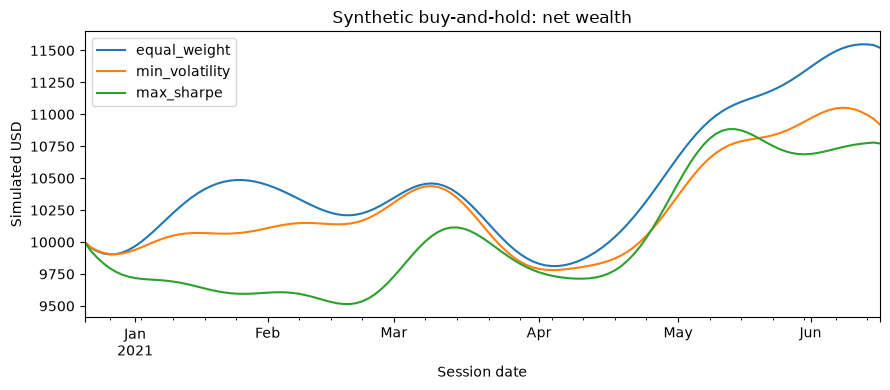

In [6]:
ax = result["trajectory"].plot(figsize=(9, 4), title="Synthetic buy-and-hold: net wealth")
ax.set(xlabel="Session date", ylabel="Simulated USD")
plt.tight_layout()
plt.show()


## 6. Contrastar casos analíticos

Con covarianza diagonal 0,04/0,09, el mínimo sin un límite adicional por activo tiene
pesos 9/13 y 4/13. Otro caso verifica que el patrimonio depende de las asignaciones
iniciales de capital, no de sumar precios crudos ni ponderar CAGR individuales.

In [7]:
labels = ["A", "B"]
mu = pd.Series([0.10, 0.11], index=labels)
covariance = pd.DataFrame(np.diag([0.04, 0.09]), index=labels, columns=labels)
analytic_weights = optimize_weights(mu, covariance, cap=1.0)
np.testing.assert_allclose(analytic_weights, [9/13, 4/13], atol=1e-6)
display(analytic_weights)
print("Volatility:", np.sqrt(analytic_weights @ covariance @ analytic_weights))
known_prices = pd.DataFrame({"A": [100., 200., 100.], "B": [10., 10., 20.]},
                           index=pd.to_datetime(["2020-01-01", "2021-01-01", "2022-01-01"]))
known_wealth, _, _ = simulate_buy_and_hold(known_prices, pd.Series({"A": .25, "B": .75}), 1000.)
np.testing.assert_allclose(known_wealth, [1000., 1250., 1750.])
display(known_wealth)


Volatility: 0.16641005886756874


A    0.692308
B    0.307692
dtype: float64

2020-01-01    1000.0
2021-01-01    1250.0
2022-01-01    1750.0
Name: wealth, dtype: float64

## Límites y reproducción

Para exportar resultados: `python -m risk_return --synthetic --output outputs/demo`.
También se admite un CSV local con metadata. Un precio faltante de un activo mantenido
en prueba invalida su evaluación: no se rellena ni cambia retrospectivamente la selección.

La investigación observada requiere componentes conocidos en cada fecha, deslistados,
ajustes/moneda verificados, calendario, retornos históricos de caja, benchmark y costos
de ejecución. Buscar parámetros no habilita reutilizar la prueba para elegir ganadores.
Este ejemplo no demuestra alpha, operabilidad ni desempeño real.

Referencias: [Sharpe (1994)](https://www-leland.stanford.edu/~wfsharpe/art/sr/SR.htm),
[SciPy SLSQP](https://docs.scipy.org/doc/scipy/reference/optimize.minimize-slsqp.html).
Las pruebas y el README documentan las convenciones contables.